# Synapse parameter learning

This notebook reuses the `parameter`, `scale` and `parameterized` of the Channel/Ion tutorials; each example has a single trainable scalar and one 1-CV voltage trace with spikes. The model and training functions live in `synapse_learning.py` in the same directory, and the notebook runs from top to bottom as is.

| Target | Parameter entry point | Gradient path | Edge cases |
|---|---|---|---|
| ExpSyn `tau`, `e` | explicit constructor signature; `synapses.trainable(...)` | continuous state/current | can be zero without effective input |
| Exp2Syn `tau1`, `tau2` | same as above | decay and the dynamically computed normalization factor | initial values must satisfy `0 < tau1 < tau2` |
| Connection `weight` | `connection.trainable(weight=...)` | floating-point event payload times the weight | a fixed NetStim needs no derivative with respect to event times |
| Detector `threshold` | `source.trainable(threshold=...)` | hard events forward, surrogate gradient backward | the same event time bin can correspond to several thresholds |
| `delay` | not trainable | fixed queue/routing | raises NotImplementedError explicitly |
| strings, wrong units/shapes | not valid numeric targets | checks at registration and in numeric operations | no whitelist of scientific parameters is maintained |

An upward crossing uses `last < threshold <= next` and a downward crossing uses `last > threshold >= next`. Reaching the threshold counts once; staying at the threshold or leaving it does not fire again. NEURON 9.0.1's APCount uses `>=` and a fixed-step NetCon uses `>`; this rule cannot be treated as identical to every NEURON detector.

Training registration happens after `init_state()`: select a discrete View again, then call `trainable()`. The training roots are separate from the physical runtime parameters: every `reset_state()` materializes the parameters from the current roots, clears dynamic states and event queues, and keeps the training roots; a full `reset()` discards the training registrations and returns to the declaration stage. Positivity and ordering constraints on parameters are checked at initialization and registration; during optimization, the user should choose a suitable parameter transform to maintain them.

In [1]:
import os
os.environ['JAX_PLATFORMS'] = 'cpu'
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(root))
import braincell
import brainstate
import brainunit as u
import jax
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from examples.optim.parameter_learning.synapse_learning import DT, build_cell, fit_one
print(f'JAX {jax.__version__}; backend={jax.default_backend()}')


JAX 0.12.0.1; backend=cpu


## 1. Fixed NetStim input: learning tau and weight

Each run fits a single factor, starting from 0.8 with a target factor of 1, on a 6 ms voltage trace with 100 Adam updates. The fixed external events have no upstream voltage to learn, so the continuous gradients of tau/weight do not depend on the event surrogate gradient.

## 2. Autapse: learning the detection threshold

Only `threshold = -20 mV + delta * mV` is learned, with delta starting at -10. The spike detector of the default Cell drives its own ExpSyn through a fixed 0.1 ms delay, and the loss is still a voltage loss. Threshold training uses a surrogate gradient and does not treat finite differences of hard events as the correct gradient.

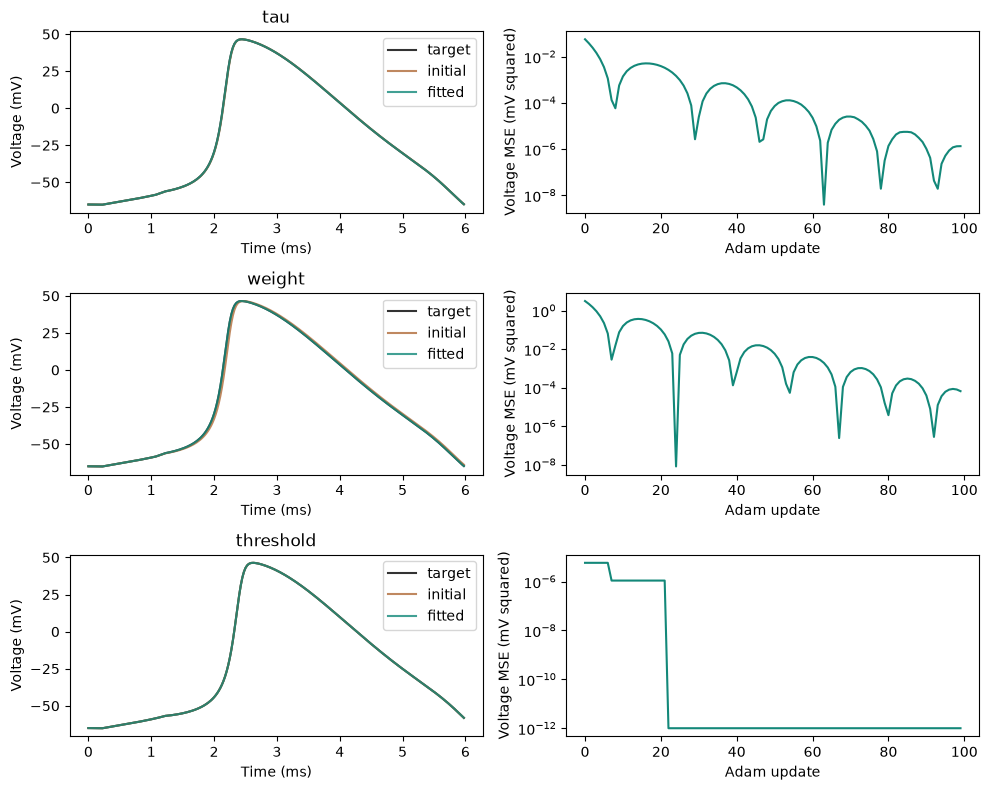

| Parameter | Initial gradient (root coordinates) | Initial MSE | Final MSE | Final root | Target spikes |
|---|---:|---:|---:|---:|---:|
| tau | -0.705719 | 0.0571876 | 1.23417e-06 | 0.998861 | 1 |
| weight | -32.935 | 3.1472 | 4.52103e-05 | 1.00079 | 1 |
| threshold | -5.34283e-05 | 5.88494e-06 | 0 | -1.01831 | 1 |

The final root of threshold is delta, not the threshold itself; the same event bins do not require delta to return exactly to 0.


In [2]:
results = []
with brainstate.environ.context(dt=DT):
    for field in ('tau', 'weight', 'threshold'):  # independent experiments, not simulation steps
        results.append(fit_one(field))
fig, axes = plt.subplots(3, 2, figsize=(10, 8))
for row, result in enumerate(results):
    times = np.arange(result['target'].size) * float(DT / u.ms)
    for key, color in [('target', 'black'), ('initial', '#b06b38'), ('fitted', '#138879')]:
        axes[row, 0].plot(times, result[key], label=key, color=color, alpha=.8)
    axes[row, 0].set(title=result['field'], xlabel='Time (ms)', ylabel='Voltage (mV)')
    axes[row, 0].legend()
    axes[row, 1].semilogy(np.maximum(result['history'], 1e-12), color='#138879')
    axes[row, 1].set(xlabel='Adam update', ylabel='Voltage MSE (mV squared)')
fig.tight_layout()
plt.show()
display(Markdown('| Parameter | Initial gradient (root coordinates) | Initial MSE | Final MSE | Final root | Target spikes |\n|---|---:|---:|---:|---:|---:|\n' + '\n'.join(
    f"| {r['field']} | {r['initial_gradient']:.6g} | {r['initial_mse']:.6g} | {r['final_mse']:.6g} | {r['fitted_root']:.6g} | {r['spikes']} |" for r in results)))
print('The final root of threshold is delta, not the threshold itself; the same event bins do not require delta to return exactly to 0.')


## 3. Automatic errors and zero gradients

Below there are no input events: the ExpSyn g starts at zero and stays at zero, so the gradient of the current with respect to tau is zero. This is not a registration failure. Wrong units, invalid time constants and delay training are rejected.

In [3]:
cell = build_cell()
cell.init_state()
cell.synapses['syn'].trainable(tau=braincell.trainable.scale(name='tau'))
cell.reset_state()
syn = cell.synapses['syn']
node = cell.runtime.get_runtime_node(syn._store.layout_id('ExpSyn'))
def silent_current():
    cell.reset_state()
    return node.current(-65.*u.mV).to_decimal(u.nA).sum()
zero = brainstate.transform.jit(brainstate.transform.grad(
    silent_current, grad_states=cell.trainables.parameters().states()))()['tau']
assert float(zero) == 0.
rows = [f'| tau, no events | gradient = {float(zero):g} |']
for label, field, value in [('tau, wrong unit', 'tau', 1.*u.mV), ('tau, non-positive', 'tau', -1.*u.ms), ('name, string', 'name', 'text')]:
    bad = build_cell()
    bad.init_state()
    try:
        bad.synapses['syn'].trainable(**{field: braincell.trainable.parameter(value)})
    except (TypeError, ValueError, KeyError) as error:
        rows.append(f'| {label} | {type(error).__name__} |')
        assert not bad.trainables.bindings()
    else:
        raise AssertionError(label)
bad = build_cell()
connection = braincell.connect('input', source=braincell.NetStim(), synapse=bad.synapses['syn'], weight=.001*u.uS)
bad.init_state()
connection = bad.connections['input']
try:
    connection.trainable(delay=braincell.trainable.parameter(.1*u.ms))
except NotImplementedError as error:
    rows.append(f'| delay | {type(error).__name__} |')
else:
    raise AssertionError('delay unexpectedly trainable')
display(Markdown('| Check | Actual result |\n|---|---|\n' + '\n'.join(rows)))


| Check | Actual result |
|---|---|
| tau, no events | gradient = 0 |
| tau, wrong unit | ValueError |
| tau, non-positive | ValueError |
| name, string | KeyError |
| delay | NotImplementedError |

## 4. BPTT / full-state RTRL

This section reuses the existing experimental RTRL and implements no new algorithm. It first compares the voltage loss and the spike loss of a single-Cell autapse, then checks a Network. The full state includes synaptic states, event queues and cross-Cell dependencies, and the parameters are fixed within one rollout; this only shows that the forward sensitivity recursion is compatible, not that updating optimizer parameters at every time step is supported.

The spike loss is `(spike - 1)^2`, which is only a derivative probe, not a biological target. With some fixed delays the feedback arrives after the surrogate function has left its effective gradient region, and then the spike-loss gradient of weight can be zero. Both algorithms must give the same result in that case.

In [4]:
from validation.optim.gradient_correctness.autapse import compare
checks = []
with brainstate.environ.context(dt=DT, precision=64):
    for mode in ('voltage', 'spike'):
        for delay_ms in (0., .1):
            result = compare(loss_kind=mode, delay=delay_ms*u.ms)
            checks.append(f"| Cell autapse | {mode} | {delay_ms:g} | {result['max_abs_error']:.3g} | {result['gradients']['weight']:.6g} |")
    result = compare(network=True, paired=True)
    checks.append(f"| Two-Cell Network | voltage | 0.1 | {result['max_abs_error']:.3g} | {result['gradients']['cell.weight']:.6g} |")
display(Markdown('| Model | Loss | Fixed delay (ms) | Max absolute gradient difference | weight gradient |\n|---|---|---:|---:|---:|\n' + '\n'.join(checks)))


| Model | Loss | Fixed delay (ms) | Max absolute gradient difference | weight gradient |
|---|---|---:|---:|---:|
| Cell autapse | voltage | 0 | 5.24e-10 | -741.38 |
| Cell autapse | voltage | 0.1 | 1.16e-10 | -792.68 |
| Cell autapse | spike | 0 | 3.77e-15 | 0.000659412 |
| Cell autapse | spike | 0.1 | 3.11e-15 | 0 |
| Two-Cell Network | voltage | 0.1 | 2.25e-12 | 0 |

## 5. Two populations, with parameters on both sides and bidirectional connections trainable together

A has 2 members and B has 3 members; each member is still 1 CV. A→B and B→A each have 6 contacts, with convergence and divergence. A receives ExpSyn and B receives Exp2Syn. Two staggered current pulses ensure that both sides keep firing after receiving feedback.

| Region | Trainable fields | Gradient-check grouping | Fitting grouping |
|---|---|---|---|
| Na channels of A and B | g_max, V_sh | independent per member | shared within each population |
| SodiumFixed of A and B | E | independent per member | shared within each population |
| ExpSyn of A | tau, e | independent per synapse | shared within A |
| Exp2Syn of B | tau1, tau2, e | independent per synapse | shared within B |
| Detectors of A and B | threshold | independent per member | shared within each population |
| A→B, B→A | weight | independent per contact | shared within each direction |

The full gradient check has 45 scalar degrees of freedom; the joint fit keeps 15. Delays are fixed and heterogeneous, and training does not change the routing. This is a check on a small bidirectional network, not an exhaustive proof for every mechanism or network size.

Below, the gmax, ion, tau and weight parameter roots are dimensionless scale factors; the shift, reversal and threshold roots are offsets in mV, not absolute voltages. A.weight corresponds to B→A and B.weight to A→B: names follow the receiving side.

In [5]:
from validation.optim.gradient_correctness.bidirectional import (
    build as build_network, gradient_comparison, fit as fit_network, DT as NETWORK_DT,
)
with brainstate.environ.context(dt=NETWORK_DT, precision=64):
    network_probe = build_network()
    activity = brainstate.transform.jit(network_probe.rollout)()
    comparison = gradient_comparison()
counts = np.asarray(activity['spike']).sum(axis=0)
assert np.all(counts >= 2), counts
display(Markdown('| Member | Spikes | Max received conductance (uS) |\n|---|---:|---:|\n' + '\n'.join(
    f'| {name} | {counts[i]:g} | {np.asarray(activity["conductance"])[:, i].max():.6g} |'
    for i, name in enumerate(['A0', 'A1', 'B0', 'B1', 'B2']))))
display(Markdown('| Parameter root | Shape | Max absolute gradient | BPTT/RTRL max absolute difference |\n|---|---|---:|---:|\n' + '\n'.join(
    f'| {name} | {gradient.shape} | {np.abs(gradient).max():.6g} | {comparison["errors"][name]:.3g} |'
    for name, gradient in comparison['gradients'].items())))
print('Total gradient coordinates:', sum(value.size for value in comparison['gradients'].values()))


| Member | Spikes | Max received conductance (uS) |
|---|---:|---:|
| A0 | 2 | 0.00112587 |
| A1 | 2 | 0.00123126 |
| B0 | 2 | 0.000751331 |
| B1 | 2 | 0.0008344 |
| B2 | 2 | 0.0009164 |

| Parameter root | Shape | Max absolute gradient | BPTT/RTRL max absolute difference |
|---|---|---:|---:|
| A.gmax | (2,) | 70371.5 | 1.31e-10 |
| A.ion | (2,) | 105331 | 4.37e-11 |
| A.reversal | (2,) | 30.3741 | 4.97e-14 |
| A.shift | (2,) | 4555.1 | 2.64e-11 |
| A.tau | (2,) | 2669.05 | 5e-12 |
| A.threshold | (2,) | 38.4637 | 1.99e-13 |
| A.weight | (6,) | 566.737 | 1.59e-12 |
| B.gmax | (3,) | 60480.7 | 9.46e-11 |
| B.ion | (3,) | 105668 | 1.75e-10 |
| B.reversal | (3,) | 121.859 | 4.26e-13 |
| B.shift | (3,) | 743.612 | 2.01e-11 |
| B.tau1 | (3,) | 450.032 | 9.66e-13 |
| B.tau2 | (3,) | 1562.53 | 2.73e-12 |
| B.threshold | (3,) | 183.281 | 3.41e-13 |
| B.weight | (6,) | 1567.9 | 3.64e-12 |

Total gradient coordinates: 45


### Joint fit: BPTT and full RTRL

Both algorithms start from the same 15 perturbed parameters and train for 100 epochs each. Parameters are fixed within each rollout and updated between epochs. The channel, ion, synapse, threshold and bidirectional weight parameters of both sides all go to the optimizer; recovering the parameters uniquely is not an acceptance criterion.

The test file additionally covers A-only and B-only losses, truncating the event backward pass while keeping the forward pass, gradient summation over shared parameters, different delays and delivery backends, prefix gradients, and cross-population / queue sensitivities.

| Method | Initial MSE | Final MSE | Final/initial |
|---|---:|---:|---:|
| bptt | 25.5107 | 0.104226 | 0.0040856 |
| rtrl | 25.5107 | 0.104226 | 0.0040856 |

| Parameter root (physical coordinates) | Initial value | BPTT fit | RTRL fit |
|---|---:|---:|---:|
| A.gmax | 0.98 | 1.02354 | 1.02354 |
| A.shift | 0.25 | 0.102729 | 0.102729 |
| A.ion | 0.98 | 1.00073 | 1.00073 |
| A.tau | 0.98 | 1.08462 | 1.08462 |
| A.reversal | 0.25 | 0.336268 | 0.336268 |
| A.threshold | 0.25 | 0.155479 | 0.155479 |
| A.weight | 0.98 | 1.07271 | 1.07271 |
| B.gmax | 1.02 | 1.01933 | 1.01933 |
| B.shift | 0.25 | 0.149915 | 0.149915 |
| B.ion | 1.02 | 0.989411 | 0.989411 |
| B.tau1 | 1.02 | 0.973852 | 0.973852 |
| B.tau2 | 1.02 | 1.01879 | 1.01879 |
| B.reversal | 0.25 | 0.332946 | 0.332946 |
| B.threshold | 0.25 | 0.0432725 | 0.0432725 |
| B.weight | 1.02 | 1.0633 | 1.0633 |

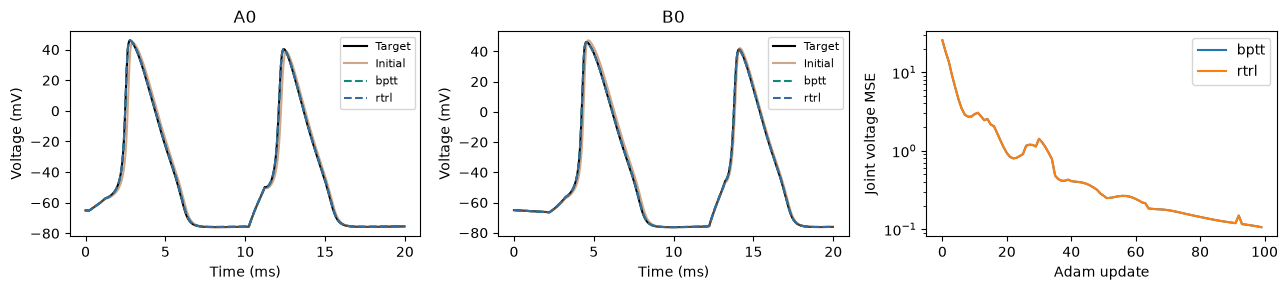

In [6]:
network_fits = []
with brainstate.environ.context(dt=NETWORK_DT, precision=64):
    for method in ('bptt', 'rtrl'):
        result = fit_network(method=method, epochs=100)
        assert np.isfinite(result['history']).all()
        assert result['final_mse'] < .1 * result['initial_mse']
        network_fits.append(result)
display(Markdown('| Method | Initial MSE | Final MSE | Final/initial |\n|---|---:|---:|---:|\n' + '\n'.join(
    f"| {r['method']} | {r['initial_mse']:.6g} | {r['final_mse']:.6g} | {r['final_mse']/r['initial_mse']:.6g} |" for r in network_fits)))
display(Markdown('| Parameter root (physical coordinates) | Initial value | BPTT fit | RTRL fit |\n|---|---:|---:|---:|\n' + '\n'.join(
    f'| {name} | {float(value):.6g} | {float(network_fits[0]["fitted_roots"][name]):.6g} | {float(network_fits[1]["fitted_roots"][name]):.6g} |'
    for name, value in network_fits[0]['initial_roots'].items())))
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
times = np.arange(network_fits[0]['target'].shape[0])*float(NETWORK_DT/u.ms)
for axis, member, title in [(axes[0], 0, 'A0'), (axes[1], 2, 'B0')]:
    axis.plot(times, network_fits[0]['target'][:, member], color='black', label='Target')
    axis.plot(times, network_fits[0]['initial'][:, member], color='#b06b38', alpha=.6, label='Initial')
    for result, color in zip(network_fits, ['#138879', '#356aa0']):
        axis.plot(times, result['fitted'][:, member], color=color, linestyle='--', label=result['method'])
    axis.set(title=title, xlabel='Time (ms)', ylabel='Voltage (mV)')
    axis.legend(fontsize=8)
for result in network_fits:
    axes[2].semilogy(result['history'], label=result['method'])
axes[2].set(xlabel='Adam update', ylabel='Joint voltage MSE')
axes[2].legend()
fig.tight_layout()
plt.show()
